Lab 15

Empirical Maximum Likelihood: Finding variance

Phys 4730 F26

   - JB

In [1]:
%reset -f
import numpy as np
import scipy.optimize as SciOpt
import scipy.stats as SciStat
import scipy.special as SciSpec
from numpy import random as rnd
from numpy import linalg as LA
import matplotlib.pyplot as plt
from scipy.stats.distributions import chi2
import matplotlib

matplotlib.rcParams.update({'font.size': 18})

/home/belz/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
### sample the Weibull distribution ###

Nsamples = 20000
Shape    =     2
rvvec    = rnd.weibull(Shape,Nsamples)

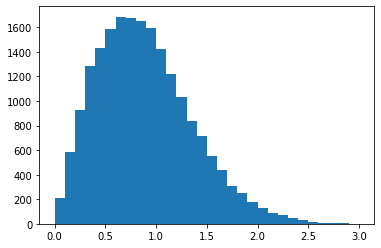

The ground truth mean is     :  0.88623 
The mean of the data is      :  0.88662 
The ground truth variance is :  0.21460 
The variance of the data is  :  0.21625 


In [3]:
### plot the results ###

fig = plt.figure()
plt.hist(rvvec,30,range=(0.0,3.0))
plt.show()

gtm = SciSpec.gamma(1.0+1.0/Shape)
gtv = SciSpec.gamma(1.0 + 2.0/Shape) - SciSpec.gamma(1.0 + 1.0/Shape)**2
obm = np.mean(rvvec)
obv = np.std(rvvec)**2

print('The ground truth mean is     : %8.5f ' % gtm)
print('The mean of the data is      : %8.5f ' % obm)
print('The ground truth variance is : %8.5f ' % gtv)
print('The variance of the data is  : %8.5f ' % obv)

In [4]:
### function to evaluate empirical likelihood ratio ###

def ELR_var(data,var):
    
    # Define the estimating function
    g = (data - gtm)**2 - var
    
    # Set up the Lagrange multiplier condition for Lam
    constraintEQN = lambda L : sum(g/(1.0 + L*g)) 
    
    # Find the multiplier
    Lam = SciOpt.fsolve(constraintEQN,0)
    
    # return the Empirical Likelihood Ratio W
    W = 2.0*np.sum(np.log(1.0 + Lam*g))
    return W
#

In [5]:
### some arrays we need ###

# Let's pick some reasonable range for possible values of the variance
x = np.linspace(obv-0.01, obv+0.01,100)

# y will hold ELR values 
y = np.zeros(len(x))

In [6]:
### for every possible variance in our range, compute ELR... ###

for ii in np.arange(0,len(x)):
    y[ii] = ELR_var(rvvec,x[ii]) 

### ...and make note of minimum ELR ###
    
cen = x[np.argmin(y)]
print("Minimum ELR:",cen)

Minimum ELR: 0.21635448026536244


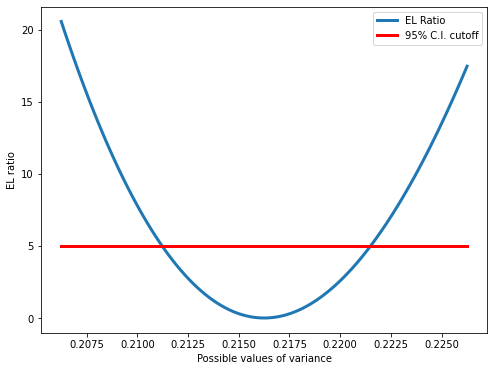

In [7]:
### now make a plot and find 95% c.i. cutoffs ###

fig = plt.figure(figsize=(8,6))

plt.plot(x,y,label='EL Ratio', linewidth=3)
plt.xlabel('Possible values of variance')
plt.ylabel('EL ratio')

ycut = np.ones(len(x))*chi2.ppf(0.975,df=1)                   
plt.plot(x,ycut,c='r',label='95% C.I. cutoff', linewidth=3)   
plt.legend()                                                  

plt.show()

In [8]:
### basically we're looking for intersections of the curves here ###

# Define cost function which sets target ELR based on confidence level
ELRiterator = lambda p : ELR_var(rvvec,p)-chi2.ppf(0.975, df=1)

# Use brent method to find high-side intersection point...
limHi = SciOpt.brentq(ELRiterator, cen, cen+0.01)

# ... and low-side intersection point
limLo = SciOpt.brentq(ELRiterator, cen-0.01, cen)

print('The ground truth variance is : %8.5f ' % gtv) 
print('The variance of the data is  : %8.5f ' % obv)
print('The 95 pct CI for MELE   : [%8.5f,%8.5f]' % (limLo,limHi))

The ground truth variance is :  0.21460 
The variance of the data is  :  0.21625 
The 95 pct CI for MELE   : [ 0.21121, 0.22151]
